**Credit Card Fraud Detection** - **Разведочный анализ данных (EDA)**

Цель работы — провести разведочный анализ данных о транзакциях
по банковским картам, выявить закономерности мошеннических
операций, изучить распределения признаков и оценить качество
исходных данных.

В качестве целевой переменной используется is_fraud:
- 0 — легальная транзакция;
- 1 — мошенническая транзакция.

**1 - Импорт библиотек**

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

import kagglehub

**2 - Загрузка датасета**

In [4]:
path = kagglehub.dataset_download("kartik2112/fraud-detection")

train = pd.read_csv(f"{path}/fraudTrain.csv", index_col=0)
test = pd.read_csv(f"{path}/fraudTest.csv", index_col=0)

print('Обучающая выборка:', train.shape)
print('Тестовая выборка:', test.shape)

100%|██████████| 202M/202M [03:38<00:00, 968kB/s]  

Extracting files...


Обучающая выборка: (1296675, 22)
Тестовая выборка: (555719, 22)


In [5]:
display(train.head())

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1296675 entries, 0 to 1296674
Data columns (total 22 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   trans_date_trans_time  1296675 non-null  object 
 1   cc_num                 1296675 non-null  int64  
 2   merchant               1296675 non-null  object 
 3   category               1296675 non-null  object 
 4   amt                    1296675 non-null  float64
 5   first                  1296675 non-null  object 
 6   last                   1296675 non-null  object 
 7   gender                 1296675 non-null  object 
 8   street                 1296675 non-null  object 
 9   city                   1296675 non-null  object 
 10  state                  1296675 non-null  object 
 11  zip                    1296675 non-null  int64  
 12  lat                    1296675 non-null  float64
 13  long                   1296675 non-null  float64
 14  city_pop               

In [7]:
print(f'Количество объектов: {train.shape[0]}')
print(f'Количество признаков: {train.shape[1]}')

display(train.dtypes)

Количество объектов: 1296675
Количество признаков: 22


trans_date_trans_time     object
cc_num                     int64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object

**Получаем следующий свод данных:**

| № | Название столбца | Описание |
|---|------------------|----------|
| 1 | index | Уникальный идентификатор для каждой строки |
| 2 | trans_date_trans_time | Дата и время транзакции |
| 3 | cc_num | Номер кредитной карты клиента |
| 4 | merchant | Название продавца |
| 5 | category | Категория продавца |
| 6 | amt | Сумма транзакции |
| 7 | first | Имя владельца кредитной карты |
| 8 | last | Фамилия владельца кредитной карты |
| 9 | gender | Пол владельца кредитной карты |
| 10 | street | Уличный адрес владельца кредитной карты |
| 11 | city | Город владельца кредитной карты |
| 12 | state | Штат владельца кредитной карты |
| 13 | zip | Почтовый индекс владельца кредитной карты |
| 14 | lat | Широта местоположения владельца карты |
| 15 | long | Долгота местоположения владельца карты |
| 16 | city_pop | Население города владельца карты |
| 17 | job | Должность владельца кредитной карты |
| 18 | dob | Дата рождения владельца кредитной карты |
| 19 | trans_num | Номер транзакции |
| 20 | unix_time | Время транзакции в формате UNIX |
| 21 | merch_lat | Широта местоположения продавца |
| 22 | merch_long | Долгота местоположения продавца |
| 23 | is_fraud | Флаг мошенничества (**целевой класс**) |

**3 - Статистические характеристики всех признаков**

In [8]:
display(train.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
trans_date_trans_time,1296675,1274791,2019-04-22 16:02:01,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cc_num,1296675.0,NaN,NaN,NaN,417192042079726656.0,1308806447000240384.0,60416207185.0,180042946491150.0,3521417320836166.0,4642255475285942.0,4992346398065154048.0
merchant,1296675,693,fraud_Kilback LLC,4403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1296675,14,gas_transport,131659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amt,1296675.0,NaN,NaN,NaN,70.351035,160.316039,1.0,9.65,47.52,83.14,28948.9
first,1296675,352,Christopher,26669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last,1296675,481,Smith,28794,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1296675,2,F,709863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street,1296675,983,0069 Robin Brooks Apt. 695,3123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,1296675,894,Birmingham,5617,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**4 - Пропуски в данных**

In [9]:
missing = pd.DataFrame({'Пропуски': train.isnull().sum()})

display(missing)

,Пропуски
trans_date_trans_time,0
cc_num,0
merchant,0
category,0
amt,0
first,0
last,0
gender,0
street,0
city,0


In [10]:
duplicates = train.duplicated().sum()

print('Количество дубликатов:', duplicates)

Количество дубликатов: 0


In [11]:
rows_with_missing = train[train.isnull().any(axis=1)]

print('Количество строк с пропусками:', len(rows_with_missing))

display(rows_with_missing)

Количество строк с пропусками: 0


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud


Важное наблюдение! мошеннические операции составляют приблизительно 0,6% размеченных транзакций. Это выраженный дисбаланс классов, который необходимо будет учитывать при построении моделей.

In [12]:
class_counts = train['is_fraud'].value_counts().sort_index()

class_percentages = train['is_fraud'].value_counts(
    normalize=True
).sort_index() * 100

class_distribution = pd.DataFrame({
    'Количество': class_counts,
    'Доля, %': class_percentages
})

class_distribution.index = ['Легальные', 'Мошеннические']

display(class_distribution.round(3))

,Количество,"Доля, %"
Легальные,1289169,99.421
Мошеннические,7506,0.579


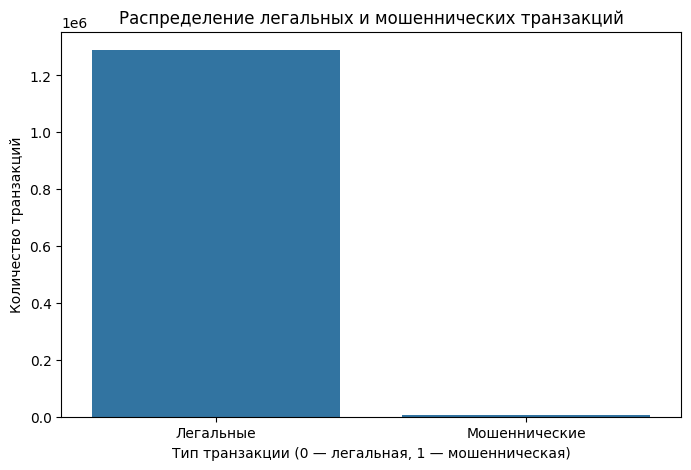

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x='is_fraud'
)

plt.title('Распределение легальных и мошеннических транзакций')
plt.xlabel('Тип транзакции (0 — легальная, 1 — мошенническая)')
plt.ylabel('Количество транзакций')
plt.xticks([0, 1], ['Легальные', 'Мошеннические'])

plt.show()

**Выводы по распределению целевой переменной**

В обучающей выборке представлено 1 296 675 транзакций,
из которых 1 289 169 являются легальными,
а 7 506 — мошенническими (0,58%).

Наблюдается выраженный дисбаланс классов. 

В дальнейшем особое внимание будет уделено метрикам
Precision, Recall, F1-score и PR-AUC.

**5 - Анализ числовых признаков**

На данном этапе рассматриваются числовые характеристики
транзакций и их взаимосвязь с целевой переменной.

Особое внимание уделяется сумме транзакции, численности
населения города и географическим координатам клиента
и торговой точки.

Идентификаторы, такие как номер банковской карты и
порядковый индекс записи, не рассматриваются как
количественные признаки.

In [14]:
numeric_features = [
    'amt',
    'city_pop',
    'lat',
    'long',
    'merch_lat',
    'merch_long'
]

display(train[numeric_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
amt,1296675.0,70.351035,160.316039,1.000000,9.650000,47.520000,83.140000,2.894890e+04
city_pop,1296675.0,88824.440563,301956.360689,23.000000,743.000000,2456.000000,20328.000000,2.906700e+06
lat,1296675.0,38.537622,5.075808,20.027100,34.620500,39.354300,41.940400,6.669330e+01
long,1296675.0,-90.226335,13.759077,-165.672300,-96.798000,-87.476900,-80.158000,-6.795030e+01
merch_lat,1296675.0,38.537338,5.109788,19.027785,34.733572,39.365680,41.957164,6.751027e+01
merch_long,1296675.0,-90.226465,13.771091,-166.671242,-96.897276,-87.438392,-80.236796,-6.695090e+01


In [15]:
display(
    train.groupby('is_fraud')[numeric_features]
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .T
)

is_fraud                      0             1
amt        mean    6.766711e+01  5.313201e+02
           median  4.728000e+01  3.965050e+02
           std     1.540080e+02  3.905601e+02
           min     1.000000e+00  1.060000e+00
           max     2.894890e+04  1.376040e+03
city_pop   mean    8.877523e+04  9.727676e+04
           median  2.456000e+03  2.623000e+03
           std     3.018065e+05  3.265815e+05
           min     2.300000e+01  2.300000e+01
           max     2.906700e+06  2.906700e+06
lat        mean    3.853689e+01  3.866361e+01
           median  3.935430e+01  3.943360e+01
           std     5.075234e+00  5.172289e+00
           min     2.002710e+01  2.002710e+01
           max     6.568990e+01  6.669330e+01
long       mean   -9.022814e+01 -8.991604e+01
           median -8.747690e+01 -8.669190e+01
           std     1.375598e+01  1.427822e+01
           min    -1.656723e+02 -1.656723e+02
           max    -6.795030e+01 -6.855650e+01
merch_lat  mean    3.853666e+01  3.865390e+01
           median  3.936528e+01  3.942701e+01
           std     5.109144e+00  5.218387e+00
           min     1.902779e+01  1.942511e+01
           max     6.668291e+01  6.751027e+01
merch_long mean   -9.022827e+01 -8.991581e+01
           median -8.744091e+01 -8.681304e+01
           std     1.376794e+01  1.429868e+01
           min    -1.666712e+02 -1.665508e+02
           max    -6.695090e+01 -6.756924e+01

Средняя сумма мошеннических транзакций примерно в 8 раза выше, чем легальных.
Однако нельзя делать вывод, что большая сумма автоматически означает мошенничество.

Средняя численность населения выглядит менее информативным, чем сумма транзакции, тк их медианы примерно одинаковы

**6 - Распределение сумм транзакций**

Сумма транзакции amt является одной из основных
характеристик операции.

Необходимо изучить распределение сумм и определить,
отличаются ли мошеннические транзакции от легальных
по размеру денежных операций.

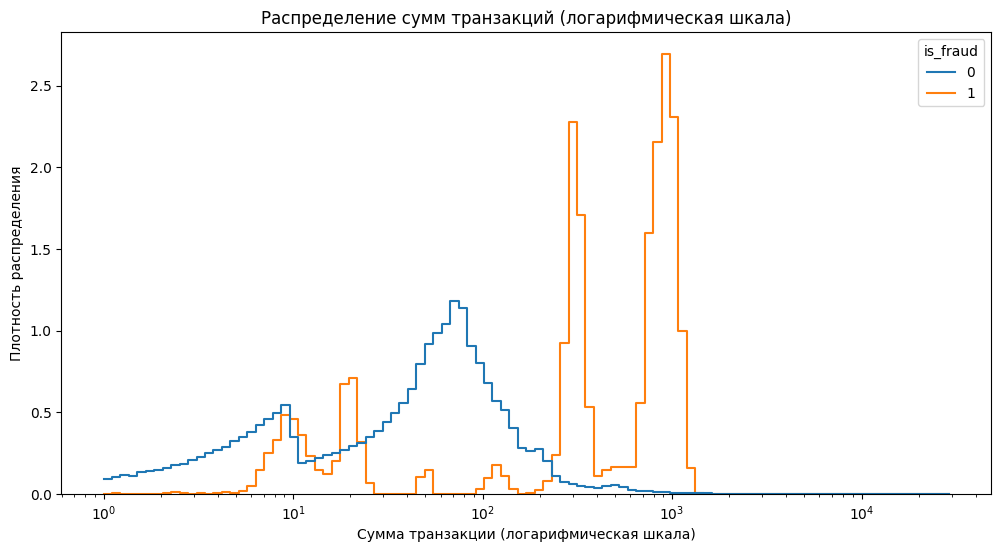

In [16]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=train,
    x='amt',
    hue='is_fraud',
    bins=100,
    stat='density',
    common_norm=False,
    element='step',
    fill=False,
    log_scale=(True, False)
)

plt.title('Распределение сумм транзакций (логарифмическая шкала)')
plt.xlabel('Сумма транзакции (логарифмическая шкала)')
plt.ylabel('Плотность распределения')
plt.show()

**7 - Проверка некорректных значений**


In [17]:
for column in numeric_features:
    print(f'\n{column}')
    print('Минимум:', train[column].min())
    print('Максимум:', train[column].max())


amt
Минимум: 1.0
Максимум: 28948.9

city_pop
Минимум: 23
Максимум: 2906700

lat
Минимум: 20.0271
Максимум: 66.6933

long
Минимум: -165.6723
Максимум: -67.9503

merch_lat
Минимум: 19.027785
Максимум: 67.510267

merch_long
Минимум: -166.671242
Максимум: -66.950902


In [18]:
print('Отрицательные суммы транзакций:',
      (train['amt'] < 0).sum())

print('Отрицательная численность населения:',
      (train['city_pop'] < 0).sum())

print('Некорректная широта клиента:',
      ((train['lat'] < -90) | (train['lat'] > 90)).sum())

print('Некорректная долгота клиента:',
      ((train['long'] < -180) | (train['long'] > 180)).sum())

print('Некорректная широта торговой точки:',
      ((train['merch_lat'] < -90) | (train['merch_lat'] > 90)).sum())

print('Некорректная долгота торговой точки:',
      ((train['merch_long'] < -180) | (train['merch_long'] > 180)).sum())

Отрицательные суммы транзакций: 0
Отрицательная численность населения: 0
Некорректная широта клиента: 0
Некорректная долгота клиента: 0
Некорректная широта торговой точки: 0
Некорректная долгота торговой точки: 0


**8 - Анализ временных признаков**

Временные характеристики транзакций могут отражать
особенности поведения клиентов и мошеннической активности.

Для анализа используются дата и время совершения операции.
На их основе выделяются час, день недели, месяц и другие
временные характеристики.

In [20]:
train['trans_date_trans_time'] = pd.to_datetime(
    train['trans_date_trans_time']
)

train['hour'] = train['trans_date_trans_time'].dt.hour
train['day_of_week'] = train['trans_date_trans_time'].dt.dayofweek
train['month'] = train['trans_date_trans_time'].dt.month
train['day'] = train['trans_date_trans_time'].dt.day
train['date'] = train['trans_date_trans_time'].dt.date

days = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

train['day_name'] = train['day_of_week'].map(days)

display(train[['trans_date_trans_time', 'hour',
               'day_name', 'month']].head())

,trans_date_trans_time,hour,day_name,month
0,2019-01-01 00:00:18,0,Tuesday,1
1,2019-01-01 00:00:44,0,Tuesday,1
2,2019-01-01 00:00:51,0,Tuesday,1
3,2019-01-01 00:01:16,0,Tuesday,1
4,2019-01-01 00:03:06,0,Tuesday,1


In [21]:
hour_fraud = train.groupby('hour').agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

hour_fraud['fraud_rate'] = (
    hour_fraud['fraud_transactions'] /
    hour_fraud['total_transactions'] * 100
)

display(hour_fraud)

,total_transactions,fraud_transactions,fraud_rate
hour,,,
0,42502,635,1.494047
1,42869,658,1.534909
2,42656,625,1.465210
3,42769,609,1.423929
4,41863,46,0.109882
5,42171,60,0.142278
6,42300,40,0.094563
7,42203,56,0.132692
8,42505,49,0.115281


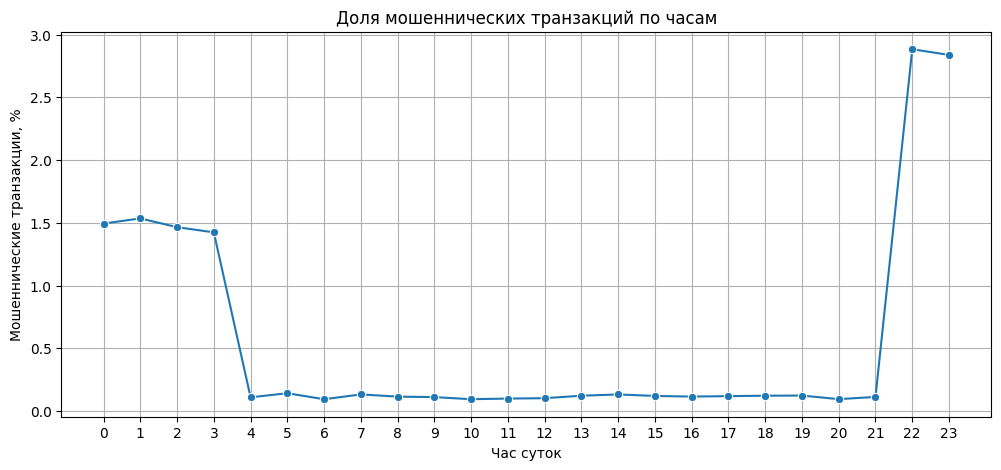

In [22]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hour_fraud,
    x=hour_fraud.index,
    y='fraud_rate',
    marker='o'
)

plt.title('Доля мошеннических транзакций по часам')
plt.xlabel('Час суток')
plt.ylabel('Мошеннические транзакции, %')
plt.xticks(range(24))
plt.grid(True)

plt.show()

**9 - Как мошенническая активность зависит от дня недели и категории покупки.**

In [25]:
day_fraud = train.groupby('day_name').agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

day_fraud['fraud_rate'] = (
    day_fraud['fraud_transactions'] /
    day_fraud['total_transactions'] * 100
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

day_fraud = day_fraud.reindex(day_order)

display(day_fraud)

,total_transactions,fraud_transactions,fraud_rate
day_name,,,
Monday,254282,1182,0.464838
Tuesday,160227,935,0.583547
Wednesday,131073,859,0.655360
Thursday,147285,1008,0.684387
Friday,152272,1079,0.708600
Saturday,200957,1227,0.610578
Sunday,250579,1216,0.485276


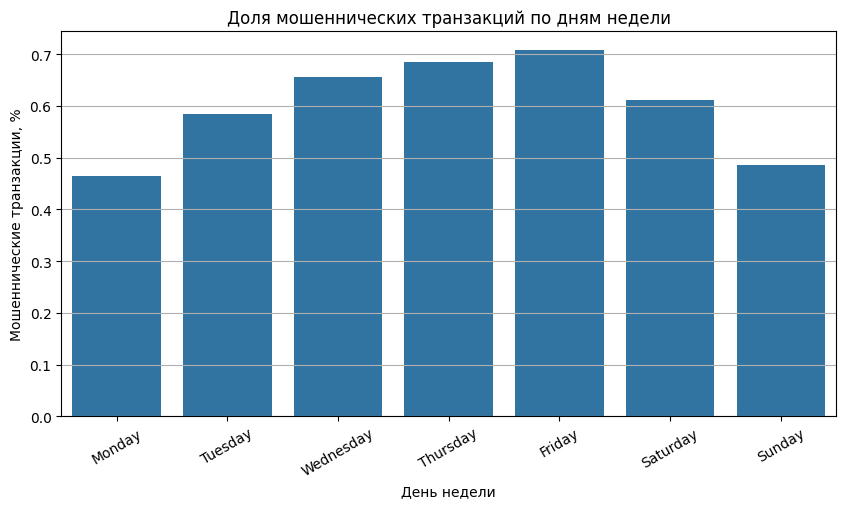

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=day_fraud.reset_index(),
    x='day_name',
    y='fraud_rate'
)

plt.title('Доля мошеннических транзакций по дням недели')
plt.xlabel('День недели')
plt.ylabel('Мошеннические транзакции, %')
plt.xticks(rotation=30)
plt.grid(axis='y')
plt.show()

In [27]:
category_fraud = train.groupby('category').agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

category_fraud['fraud_rate'] = (
    category_fraud['fraud_transactions'] /
    category_fraud['total_transactions'] * 100
)

category_fraud = category_fraud.sort_values(
    by='fraud_rate',
    ascending=False
)

display(category_fraud)

,total_transactions,fraud_transactions,fraud_rate
category,,,
shopping_net,97543,1713,1.756149
misc_net,63287,915,1.445795
grocery_pos,123638,1743,1.409761
shopping_pos,116672,843,0.722538
gas_transport,131659,618,0.469394
misc_pos,79655,250,0.313853
grocery_net,45452,134,0.294817
travel,40507,116,0.286370
entertainment,94014,233,0.247835


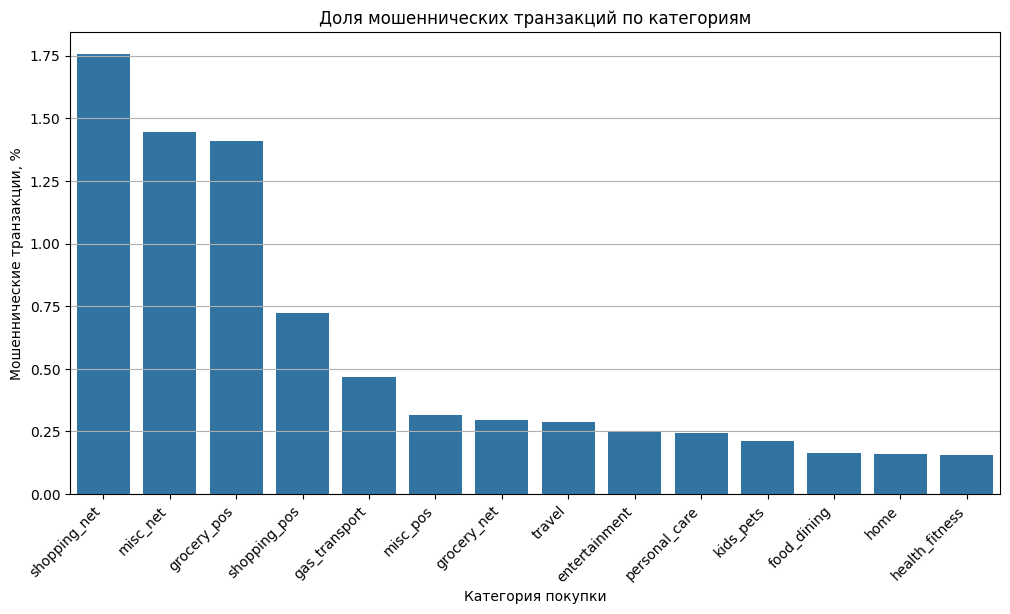

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_fraud.reset_index(),
    x='category',
    y='fraud_rate'
)

plt.title('Доля мошеннических транзакций по категориям')
plt.xlabel('Категория покупки')
plt.ylabel('Мошеннические транзакции, %')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.show()

**10 - Анализ географических признаков**

In [ ]:
lat1 = np.radians(train['lat'])
lon1 = np.radians(train['long'])
lat2 = np.radians(train['merch_lat'])
lon2 = np.radians(train['merch_long'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2 +
    np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a))

train['distance_km'] = 6371 * c

display(train[['lat', 'long', 'merch_lat', 'merch_long', 'distance_km']].head())

,lat,long,merch_lat,merch_long,distance_km
0,36.0788,-81.1781,36.011293,-82.048315,78.597568
1,48.8878,-118.2105,49.159047,-118.186462,30.212176
2,42.1808,-112.2620,43.150704,-112.154481,108.206083
3,46.2306,-112.1138,47.034331,-112.561071,95.673231
4,38.4207,-79.4629,38.674999,-78.632459,77.556744


In [33]:
display(
    train.groupby('is_fraud')['distance_km']
    .agg(['mean', 'median', 'std', 'min', 'max'])
)

,mean,median,std,min,max
is_fraud,,,,,
0,76.113756,78.233012,29.119051,0.022255,152.117173
1,76.268330,77.931954,28.752602,0.738769,144.522410


In [32]:
train['distance_group'] = pd.cut(
    train['distance_km'],
    bins=[0, 10, 25, 50, 100, 200, 500, float('inf')],
    labels=['0–10', '10–25', '25–50', '50–100',
            '100–200', '200–500', '500+']
)

distance_fraud = train.groupby(
    'distance_group',
    observed=False
).agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

distance_fraud['fraud_rate'] = (
    distance_fraud['fraud_transactions'] /
    distance_fraud['total_transactions'] * 100
)

display(distance_fraud)

,total_transactions,fraud_transactions,fraud_rate
distance_group,,,
0–10,10566,53,0.501609
10–25,55635,302,0.542824
25–50,198995,1128,0.566848
50–100,728628,4276,0.586856
100–200,302851,1747,0.576851
200–500,0,0,NaN
500+,0,0,NaN


По расстоянию получен интересный результат, среднее расстояние для легальных транзакций составляет 76,11 км, для мошеннических 76,27 км. Медианы также практически совпадают 78,23 и 77,93 км соответственно.

**11 - Анализ возраста клиентов**

In [34]:
train['dob'] = pd.to_datetime(train['dob'])

train['age'] = (
    train['trans_date_trans_time'].dt.year -
    train['dob'].dt.year -
    (
        (train['trans_date_trans_time'].dt.month < train['dob'].dt.month) |
        (
            (train['trans_date_trans_time'].dt.month == train['dob'].dt.month) &
            (train['trans_date_trans_time'].dt.day < train['dob'].dt.day)
        )
    ).astype(int)
)

display(train[['dob', 'trans_date_trans_time', 'age']].head())

,dob,trans_date_trans_time,age
0,1988-03-09,2019-01-01 00:00:18,30
1,1978-06-21,2019-01-01 00:00:44,40
2,1962-01-19,2019-01-01 00:00:51,56
3,1967-01-12,2019-01-01 00:01:16,51
4,1986-03-28,2019-01-01 00:03:06,32


In [35]:
display(
    train.groupby('is_fraud')['age']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
)

,count,mean,median,std,min,max
is_fraud,,,,,,
0,1289169,45.480620,43.0,17.386910,13,95
1,7506,48.289369,47.0,18.848792,14,93


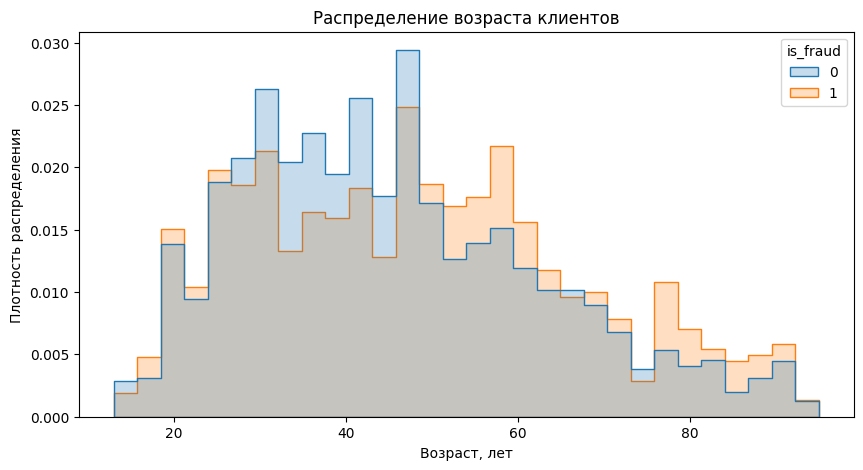

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x='age',
    hue='is_fraud',
    bins=30,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Распределение возраста клиентов')
plt.xlabel('Возраст, лет')
plt.ylabel('Плотность распределения')
plt.show()

In [37]:
train['age_group'] = pd.cut(
    train['age'],
    bins=[0, 20, 30, 40, 50, 60, 70, 100],
    labels=['до 20', '20–30', '30–40', '40–50',
            '50–60', '60–70', '70+']
)

age_fraud = train.groupby(
    'age_group',
    observed=False
).agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

age_fraud['fraud_rate'] = (
    age_fraud['fraud_transactions'] /
    age_fraud['total_transactions'] * 100
)

display(age_fraud)

,total_transactions,fraud_transactions,fraud_rate
age_group,,,
до 20,50691,295,0.581957
20–30,220073,1277,0.580262
30–40,288021,1247,0.432955
40–50,298477,1420,0.475749
50–60,184835,1394,0.754186
60–70,128671,837,0.650496
70+,125907,1036,0.822830


При анализе возрастных групп выявлены различия в доле мошеннических операций. Наибольший показатель наблюдается среди клиентов старше 70 лет и составляет 0,823%. Также относительно высокая доля мошенничества отмечается в группах 50–60 лет (0,754%) и 60–70 лет (0,650%).

Наименьшая доля мошеннических транзакций зафиксирована среди клиентов 30–40 лет.

**12 - Корреляционный анализ признаков**

In [38]:
corr_features = [
    'amt',
    'city_pop',
    'lat',
    'long',
    'merch_lat',
    'merch_long',
    'distance_km',
    'age',
    'hour',
    'day_of_week',
    'is_fraud'
]

corr_data = train[corr_features].corr()

display(
    corr_data['is_fraud']
    .drop('is_fraud')
    .sort_values(key=abs, ascending=False)
)

amt            0.219404
hour           0.013799
age            0.012248
city_pop       0.002136
lat            0.001894
merch_lat      0.001741
day_of_week    0.001739
merch_long     0.001721
long           0.001721
distance_km    0.000403
Name: is_fraud, dtype: float64

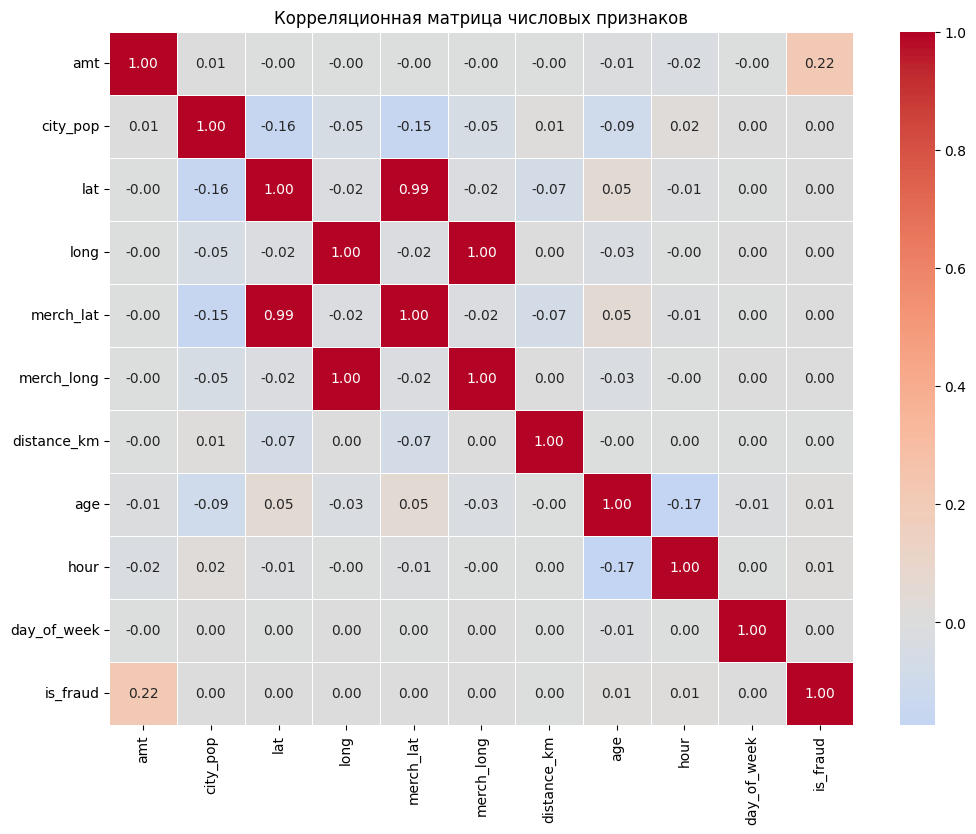

In [39]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_data,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Корреляционная матрица числовых признаков')
plt.show()

По результатам корреляционного анализа наиболее выраженная связь с целевой переменной is_fraud обнаружена у признака amt.

Для остальных числовых признаков линейная корреляция с целевой переменной близка к нулю. Однако это не исключает наличия нелинейных зависимостей, которые могут быть выявлены алгоритмами машинного обучения.

Также обнаружена высокая корреляция между географическими координатами клиента и торговой точки: коэффициенты корреляции lat и merch_lat составляют 0,99, а long и merch_long — 1,00. При дальнейшем построении модели следует учитывать возможную избыточность этих признаков.

**13 - Анализ по полу и штату**

In [40]:
gender_fraud = train.groupby('gender').agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

gender_fraud['fraud_rate'] = (
    gender_fraud['fraud_transactions'] /
    gender_fraud['total_transactions'] * 100
)

display(gender_fraud)

,total_transactions,fraud_transactions,fraud_rate
gender,,,
F,709863,3735,0.526158
M,586812,3771,0.642625


In [44]:
state_fraud = train.groupby('state').agg(
    total_transactions=('is_fraud', 'count'),
    fraud_transactions=('is_fraud', 'sum')
)

state_fraud['fraud_rate'] = (
    state_fraud['fraud_transactions'] /
    state_fraud['total_transactions'] * 100
)

state_fraud = state_fraud.sort_values(
    by='fraud_rate',
    ascending=False
)

display(state_fraud.head(10))

,total_transactions,fraud_transactions,fraud_rate
state,,,
DE,9,9,100.000000
RI,550,15,2.727273
AK,2120,36,1.698113
NV,5607,47,0.838238
CO,13880,113,0.814121
OR,18597,149,0.801204
TN,17554,140,0.797539
NE,24168,180,0.744786
ME,16505,119,0.720994


При анализе пола клиентов выявлено, что доля мошеннических транзакций среди мужчин составляет 0,643%, а среди женщин 0,526%. 

При анализе распределения мошеннических операций по штатам обнаружены различия между регионами. Наибольшая доля наблюдается в штате DE, однако количество транзакций составляет всего 9, поэтому данный результат нельзя считать показательным. Среди штатов с большим количеством наблюдений выделяется RI с долей мошеннических операций 2,727%.

**14 - Анализ количества уникальных значений категориальных признаков**

In [45]:
categorical_features = [
    'merchant',
    'category',
    'gender',
    'state',
    'city',
    'job'
]

for col in categorical_features:
    print(f'{col}: {train[col].nunique()} уникальных значений')

merchant: 693 уникальных значений
category: 14 уникальных значений
gender: 2 уникальных значений
state: 51 уникальных значений
city: 894 уникальных значений
job: 494 уникальных значений


In [46]:
for col in categorical_features:
    print(f'\nПризнак: {col}')
    display(train[col].value_counts().head(10))


Признак: merchant


merchant
fraud_Kilback LLC                   4403
fraud_Cormier LLC                   3649
fraud_Schumm PLC                    3634
fraud_Kuhn LLC                      3510
fraud_Boyer PLC                     3493
fraud_Dickinson Ltd                 3434
fraud_Cummerata-Jones               2736
fraud_Kutch LLC                     2734
fraud_Olson, Becker and Koch        2723
fraud_Stroman, Hudson and Erdman    2721
Name: count, dtype: int64


Признак: category


category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
Name: count, dtype: int64


Признак: gender


gender
F    709863
M    586812
Name: count, dtype: int64

... (2 outputs left out)


Признак: city


city
Birmingham     5617
San Antonio    5130
Utica          5105
Phoenix        5075
Meridian       5060
Thomas         4634
Conway         4613
Cleveland      4604
Warren         4599
Houston        4168
Name: count, dtype: int64


Признак: job


job
Film/video editor             9779
Exhibition designer           9199
Naval architect               8684
Surveyor, land/geomatics      8680
Materials engineer            8270
Designer, ceramics/pottery    8225
Systems developer             7700
IT trainer                    7679
Financial adviser             7659
Environmental consultant      7547
Name: count, dtype: int64

In [47]:
display(
    train.groupby(['category', 'gender'], observed=True)
    ['is_fraud']
    .agg(['count', 'sum', 'mean'])
    .sort_values('mean', ascending=False)
    .head(15)
)

count   sum      mean
category      gender                       
shopping_net  M       42208  1027  0.024332
misc_net      M       27648   523  0.018916
grocery_pos   M       58226   992  0.017037
shopping_net  F       55335   686  0.012397
grocery_pos   F       65412   751  0.011481
misc_net      F       35639   392  0.010999
shopping_pos  M       48841   386  0.007903
              F       67831   457  0.006737
gas_transport M       58992   363  0.006153
misc_pos      F       42378   165  0.003894
grocery_net   M       20178    77  0.003816
gas_transport F       72667   255  0.003509
travel        F       20122    66  0.003280
entertainment F       48189   146  0.003030
kids_pets     F       62877   190  0.003022

Наименьшую кардинальность имеют признаки gender (2 значения) и category (14 значений). Наибольшее количество уникальных значений наблюдается у признаков city, merchant и job.

Это необходимо учитывать при подготовке данных к моделированию. Для признаков с небольшим количеством категорий может применяться One-Hot Encoding. Для признаков с высокой - целесообразно рассмотреть альтернативные способы кодирования, позволяющие избежать чрезмерного увеличения размерности датасета.

**ВЫВОД по результатам EDA**

В ходе разведочного анализа датасета выявлено сильное несбалансированное распределение целевой переменной: мошеннические транзакции составляют всего 0,58% от общего количества операций. Пропущенные значения и полные дубликаты отсутствуют.

Наиболее заметные различия между легальными и мошенническими операциями обнаружены в сумме транзакции amt и времени её совершения. Также выявлены закономерности, связанные с возрастом клиентов, категорией покупки, полом и штатом.

Корреляционный анализ показал, что наиболее выраженная линейная связь с целевой переменной наблюдается у суммы транзакции. По результатам анализа сформированы дополнительные признаки: возраст клиента, час совершения операции и расстояние до торговой точки.

Полученные результаты позволили определить значимые признаки и подготовить основу для дальнейшей обработки данных и построения моделей машинного обучения.